# Lecture 4 examples: random variables and distributions

We compare outcomes, values of random variables, and their distributions. In every simulation, the probability model is fixed and the generated observations are random. We display the random seed so that each computation is reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(20260811)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. One sample space, several random variables

Roll two fair dice independently. The sample space is $\Omega\coloneqq\{1,\ldots,6\}^2$, with the power-set sigma-algebra and probability $1/36$ for each outcome. Define $X(\omega_1,\omega_2)\coloneqq\omega_1+\omega_2$ for every $(\omega_1,\omega_2)\in\Omega$. The function $X$ sends 36 outcomes to 11 possible sums. The left plot shows those sums; the right plot shows the probabilities obtained by counting their preimages.

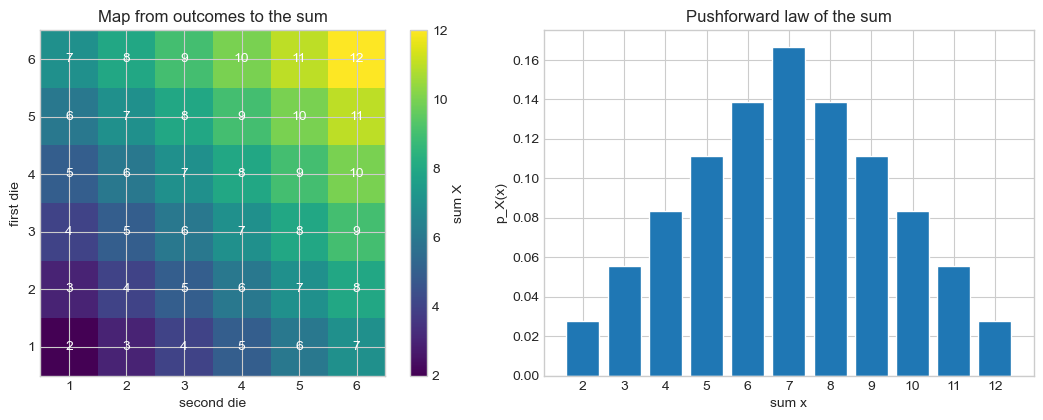

support: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
preimage counts: [1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]


In [4]:
outcomes = np.array([(first, second) for first in range(1, 7) for second in range(1, 7)])
dice_sums = outcomes.sum(axis=1)
sum_values, preimage_counts = np.unique(dice_sums, return_counts=True)
sum_pmf = preimage_counts / len(outcomes)

sum_grid = np.add.outer(np.arange(1, 7), np.arange(1, 7))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
image = axes[0].imshow(sum_grid, cmap="viridis", origin="lower")
axes[0].set_xticks(range(6), labels=range(1, 7))
axes[0].set_yticks(range(6), labels=range(1, 7))
axes[0].set_xlabel("second die")
axes[0].set_ylabel("first die")
axes[0].set_title("Map from outcomes to the sum")
for row in range(6):
    for col in range(6):
        axes[0].text(col, row, sum_grid[row, col], ha="center", va="center", color="white")
fig.colorbar(image, ax=axes[0], label="sum X")

axes[1].bar(sum_values, sum_pmf, color="tab:blue", edgecolor="white")
axes[1].set_xticks(sum_values)
axes[1].set_xlabel("sum x")
axes[1].set_ylabel("p_X(x)")
axes[1].set_title("Pushforward law of the sum")
plt.tight_layout()
plt.show()

print("support:", sum_values.tolist())
print("preimage counts:", preimage_counts.tolist())
assert preimage_counts.sum() == 36
assert np.isclose(sum_pmf.sum(), 1.0)

## 2. Exact PMF versus simulated relative frequencies

We simulate 20,000 independent repetitions of the two-dice experiment. For each possible sum, we compare its relative frequency in the simulated sample with its probability under the fixed model. The reported maximum absolute PMF error is the largest absolute difference between these two quantities over the sums $2,\ldots,12$. A different random sample generally gives different relative frequencies.

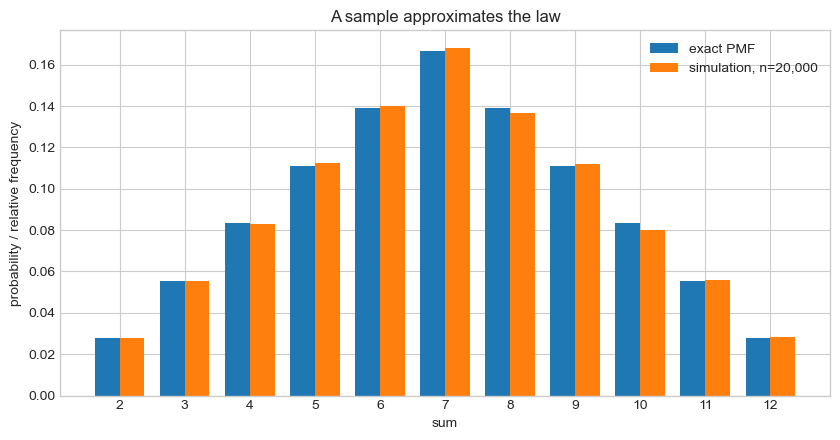

maximum absolute PMF error: 0.0032


In [7]:
n_rolls = 20_000
simulated_dice = rng.integers(1, 7, size=(n_rolls, 2))
simulated_sums = simulated_dice.sum(axis=1)
empirical_pmf = np.array([(simulated_sums == value).mean() for value in sum_values])

width = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(sum_values - width / 2, sum_pmf, width=width, label="exact PMF")
ax.bar(sum_values + width / 2, empirical_pmf, width=width, label=f"simulation, n={n_rolls:,}")
ax.set_xticks(sum_values)
ax.set_xlabel("sum")
ax.set_ylabel("probability / relative frequency")
ax.set_title("A sample approximates the law")
ax.legend()
plt.tight_layout()
plt.show()

print(f"maximum absolute PMF error: {np.max(np.abs(empirical_pmf - sum_pmf)):.4f}")

## 3. A continuous transformation

Let $X$ be uniformly distributed on $[0,1]$, and define $Y\coloneqq X^2$. For every $y\in\mathbb R$, the CDF is $F_Y(y)=0$ if $y<0$, $F_Y(y)=\sqrt y$ if $0\le y<1$, and $F_Y(y)=1$ if $y\ge1$. Moreover, $F_Y^{-1}(u)=u^2$ for every $u\in(0,1)$.

We define one density $f_Y:\mathbb R\to[0,\infty)$, for every $y\in\mathbb R$, by

$$
f_Y(y)\coloneqq\begin{cases}1/(2\sqrt y),&0<y<1,\\0,&\text{otherwise}.\end{cases}
$$

The function $f_Y$ is defined at every real number, but the law of $Y$ does not determine its density uniquely. In particular, replacing either endpoint value by another nonnegative number leaves all probability integrals unchanged. Our choice is $f_Y(0)=f_Y(1)=0$. For every $y\in\mathbb R$, integrating $f_Y$ over $(-\infty,y]$ gives $F_Y(y)$. At each point where the chosen density is continuous, $F_Y'(y)=f_Y(y)$.

We now generate 50,000 independent observations from the uniform model, square each observation, and compare the normalized histogram with the fixed density $f_Y$.

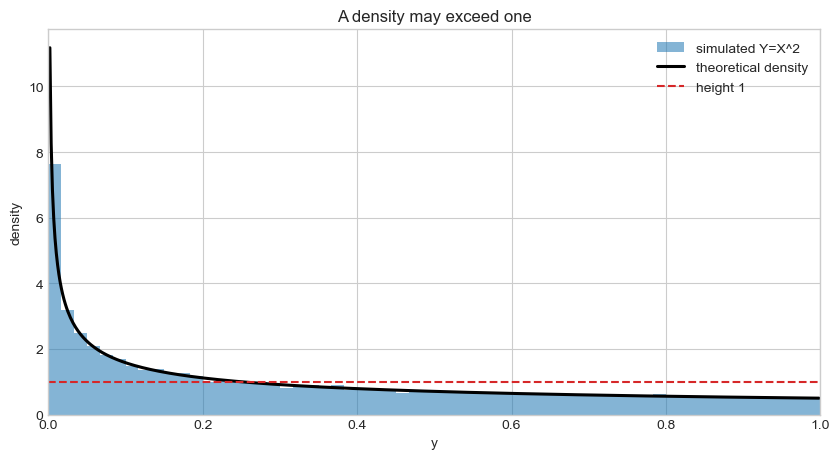

In [10]:
unit_uniform = stats.uniform(loc=0.0, scale=1.0)
n_population = 50_000
x_sample = unit_uniform.rvs(size=n_population, random_state=rng)
y_sample = x_sample**2

y_grid = np.linspace(0.002, 1.0, 600, endpoint=False)
density_y = 1.0 / (2.0 * np.sqrt(y_grid))

fig, ax = plt.subplots(figsize=(8.5, 4.7))
ax.hist(y_sample, bins=60, density=True, alpha=0.55, label="simulated Y=X^2")
ax.plot(y_grid, density_y, color="black", linewidth=2.2, label="theoretical density")
ax.axhline(1.0, color="tab:red", linestyle="--", label="height 1")
ax.set_xlim(0, 1)
ax.set_xlabel("y")
ax.set_ylabel("density")
ax.set_title("A density may exceed one")
ax.legend()
plt.tight_layout()
plt.show()

assert np.all((0 <= y_sample) & (y_sample <= 1))

## 4. Empirical CDFs and sample size

For $n\in\mathbb N$ and fixed observations $y_1,\ldots,y_n\in\mathbb R$, define $\widehat F_n(y)\coloneqq n^{-1}\sum_{i=1}^n\mathbf 1_{\{y_i\le y\}}$ for every $y\in\mathbb R$. Thus $\widehat F_n(y)$ is the fraction of observations not exceeding $y$. A value observed $k$ times produces a jump of size $k/n$.

For each sample size, we generate independent observations of $Y=X^2$, where $X$ is uniform on $[0,1]$. The samples change, but the model CDF $F_Y$ remains fixed. We compare both empirical CDFs with $F_Y$; one comparison does not guarantee that the larger sample is closer at every threshold.

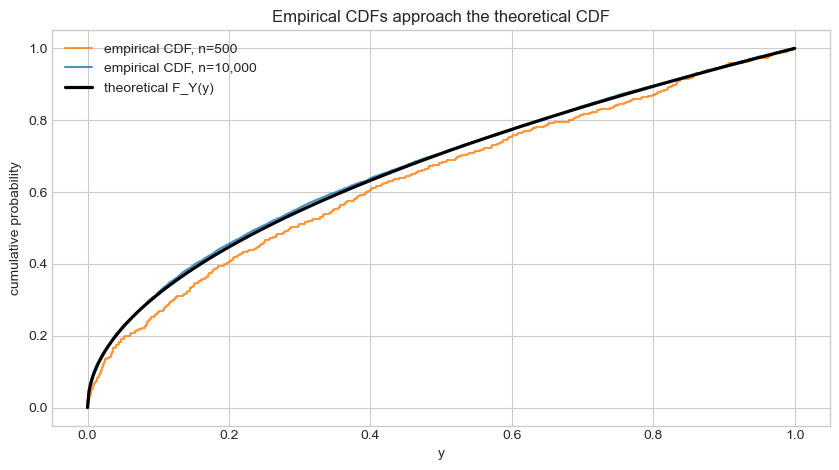

In [13]:
def ecdf(sample):
    ordered = np.sort(sample)
    cumulative = np.arange(1, len(ordered) + 1) / len(ordered)
    return ordered, cumulative

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for n_samples, color in [(500, "tab:orange"), (10_000, "tab:blue")]:
    x_now = unit_uniform.rvs(size=n_samples, random_state=rng)
    y_now = x_now**2
    ordered, cumulative = ecdf(y_now)
    ax.step(ordered, cumulative, where="post", color=color, alpha=0.8, label=f"empirical CDF, n={n_samples:,}")

cdf_grid = np.linspace(0, 1, 500)
ax.plot(cdf_grid, np.sqrt(cdf_grid), color="black", linewidth=2.3, label="theoretical F_Y(y)")
ax.set_xlabel("y")
ax.set_ylabel("cumulative probability")
ax.set_title("Empirical CDFs approach the theoretical CDF")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Quantiles as the inverse direction

For each $u\in(0,1)$, the quantile $F_Y^{-1}(u)$ is the smallest threshold at which the CDF reaches or exceeds $u$. For a fixed sample with empirical CDF $\widehat F_n$, define $\widehat F_n^{-1}(u)\coloneqq\inf\{y\in\mathbb R:\widehat F_n(y)\ge u\}$ for every $u\in(0,1)$. These empirical quantiles depend on the sample, while $F_Y^{-1}(u)=u^2$ is fixed by the model.

We use `np.quantile(..., method="inverted_cdf")` to implement the generalized inverse of the empirical CDF. NumPy's default interpolation convention can return a value between observations and would not implement this definition.

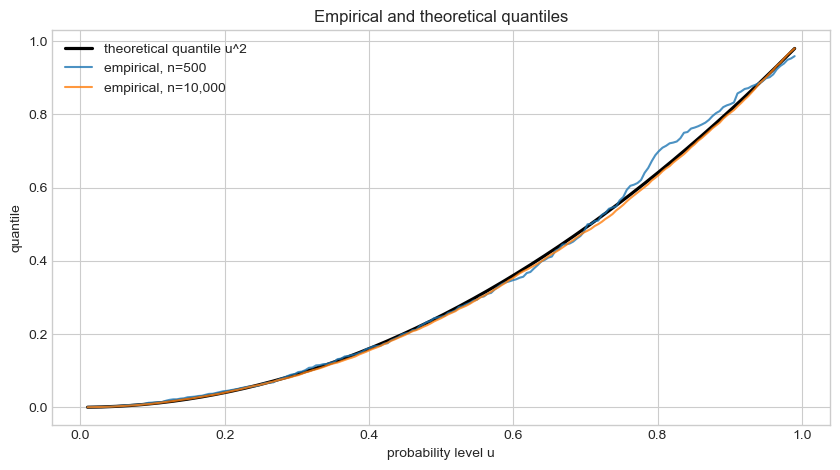

levels:               [0.1 0.5 0.9]
theoretical values:   [0.01 0.25 0.81]
large-sample values:  [0.01024556 0.25097983 0.81080184]


In [16]:
u_grid = np.linspace(0.01, 0.99, 199)
theoretical_quantiles = u_grid**2
sample_sizes = [500, 10_000]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(u_grid, theoretical_quantiles, color="black", linewidth=2.3, label="theoretical quantile u^2")
for n_samples in sample_sizes:
    sample = unit_uniform.rvs(size=n_samples, random_state=rng) ** 2
    ax.plot(u_grid, np.quantile(sample, u_grid, method="inverted_cdf"), alpha=0.8, label=f"empirical, n={n_samples:,}")
ax.set_xlabel("probability level u")
ax.set_ylabel("quantile")
ax.set_title("Empirical and theoretical quantiles")
ax.legend()
plt.tight_layout()
plt.show()

levels = np.array([0.1, 0.5, 0.9])
print("levels:              ", levels)
print("theoretical values:  ", levels**2)
print("large-sample values: ", np.quantile(y_sample, levels, method="inverted_cdf"))

## Exercises

*Presentation format:* Define the objects and assumptions, show the intermediate argument or computation, and finish with a clear conclusion. For the Python/data task, bring one informative figure and explain what it demonstrates.

1. **Conceptual: an exact value and a rounded display.** Let $X$ be an idealized measurement uniformly distributed on $[0,1]$. We choose the density $f_X(x)\coloneqq1$ for every $x\in(0,1)$ and $f_X(x)\coloneqq0$ otherwise. Let $Y$ be the value obtained by rounding $X$ to the nearest hundredth; if $X$ is exactly halfway between two such values, round upward. For example, the unrounded value $0.3718$ produces the displayed value $0.37$. Thus $X$ is the unrounded measurement, whereas $Y$ is the number on the display.

    1. Suppose the display reads $0.37$. Determine the interval of possible values of $X$, including which endpoints belong to the interval. Express the event $\{Y=0.37\}$ in terms of $X$, and sketch the interval on a number line. Use the sketch to explain whether the display determines $X$ exactly.

    2. Now consider a new measurement, before observing its display. Under the stated uniform model, calculate

        $$
        \begin{gathered}
        F_X(0.37)=\mathbb P(X\le0.37),\qquad
        \mathbb P(X=0.37),\\
        \mathbb P(Y=0.37),\qquad
        f_X(0.37).
        \end{gathered}
        $$

        These are unconditional quantities: do not condition on the display reading $0.37$. Show each calculation and explain what the quantity describes.

    3. Use the interval from part 1 and the calculations from part 2 to explain why $\mathbb P(Y=0.37)>0$ and $\mathbb P(X=0.37)=0$ do not contradict each other. Distinguish the density value $f_X(0.37)$ from the probability obtained by integrating $f_X$ over that interval.

2. **Mathematical.** Let $X$ be uniformly distributed on $[0,2]$, with density $f_X(x)\coloneqq1/2$ for every $x\in(0,2)$ and $f_X(x)\coloneqq0$ otherwise. Define $Y\coloneqq X^2$. Derive the CDF $F_Y(y)$ and one density $f_Y(y)$ for every $y\in\mathbb R$, specifying any chosen endpoint values. Then derive $F_Y^{-1}(u)$ for every $u\in(0,1)$.

3. **Python/data.** Use `lecture_04_examples.ipynb` as a starting point. For each sample size $n\in\{500,10\,000\}$, generate $n$ independent observations $x_1,\ldots,x_n$ from the uniform model on $[0,2]$ in Exercise 2, and set $y_i\coloneqq x_i^2$ for every $i\in\{1,\ldots,n\}$. Keep the model and a reported random seed fixed throughout the comparison.

    1. Define $\widehat F_n(y)\coloneqq n^{-1}\sum_{i=1}^n\mathbf 1_{\{y_i\le y\}}$ for every $y\in\mathbb R$. Plot both empirical CDFs together with the theoretical CDF $F_Y$ from Exercise 2.

    2. Use the same grid $G\coloneqq\{4j/1000:j=0,\ldots,1000\}$ for both sample sizes. Report the maximum absolute difference on this grid,

        $$
        D_n\coloneqq\max_{y\in G}\bigl|\widehat F_n(y)-F_Y(y)\bigr|.
        $$


    3. Tabulate $\widehat F_n^{-1}(u)$ and $F_Y^{-1}(u)$ for each $u\in\{0.1,0.5,0.9\}$. Use `method="inverted_cdf"` in `np.quantile` to match the generalized-inverse definition.

    4. Describe the differences visible in your plots and tables. Does the larger sample have the smaller value of $D_n$ in this run? Explain why a comparison of two simulated samples does not guarantee the same ordering in every run.
    

4. **Additional mathematical exercise: a non-monotone transformation.** Let $X$ be uniformly distributed on $[-1,2]$, with density $f_X(x)\coloneqq1/3$ for every $x\in(-1,2)$ and $f_X(x)\coloneqq0$ otherwise. Define $Y\coloneqq X^2$.

    1. Sketch the function $x\mapsto x^2$ on $[-1,2]$. For every $y\ge0$, express $\{Y\le y\}$ in terms of $X$. Then derive $F_Y(y)$ for every $y\in\mathbb R$, accounting for both square roots and the endpoints of $[-1,2]$. Use the sketch to explain why the formula for strictly increasing transformations does not apply on the whole interval.

    2. Find one density $f_Y:\mathbb R\to[0,\infty)$ of $Y$. Specify $f_Y(y)$ for every $y\in\mathbb R$, including the endpoints of each interval in your piecewise definition. Verify that

        $$
        \int_{-\infty}^{y}f_Y(t)\,\mathrm dt=F_Y(y)
        \qquad\text{for every }y\in\mathbb R.
        $$


    3. Determine $F_Y^{-1}(u)$ for every $u\in(0,1)$, using the definition of the generalized inverse. In particular, compute the median $F_Y^{-1}(1/2)$.

    4. Fix $y\in(0,4]$. First verify that $\mathbb P(Y\le y)>0$, and then compute $\mathbb P(X<0\mid Y\le y)$. Determine for which $y$ this conditional probability is greater than, equal to, or less than $\mathbb P(X<0)$. Explain the comparison using the intervals of possible values of $X$.